# Unified Logarithmic Potential

This notebook applies the Metropolis–Hastings exchange from `05_log_potential.ipynb` with the unified potential

$$U(w) = A\log\left(1 + \frac{w}{w_0}\right).$$

For $w \ll w_0$ the potential is approximately linear, $U(w) \approx A w / w_0$, so the bulk of the distribution behaves like the exponential DY regime. For $w \gg w_0$ it is logarithmic, which produces a power-law tail. The scale $w_0$ sets where the crossover happens, and $A$ sets the steepness of the tail.

The one-agent Gibbs weight is

$$e^{-\beta U(w)} = \left(1 + \frac{w}{w_0}\right)^{-\beta A},$$

which gives the two regimes directly:

- **Bulk** ($w \ll w_0$): $p(w) \approx \frac{\beta A - 1}{w_0}\, e^{-\beta A\, w / w_0}$, an exponential, as in the DY model
- **Tail** ($w \gg w_0$): $p(w) \sim w^{-\beta A}$, a Pareto tail, so the CCDF decays as $P(W > w) \sim w^{-(\beta A - 1)}$

Total wealth is conserved, which matters here. For $\beta A > 2$ there is a critical mean wealth $\rho_c = w_0 / (\beta A - 2)$. Below it the tail is exponentially tilted, and above it the excess wealth condenses onto a single agent. The parameters are therefore chosen to sit exactly at criticality, where the stationary distribution is exactly this one-agent weight (a Lomax, or Pareto Type II, distribution):

- $\bar w = 1$ (mean wealth), $\beta = 1$, $A = 2.5$, $w_0 = 0.5$, giving $\rho_c = 0.5 / 0.5 = 1 = \bar w$
- Bulk: $p(w) \approx 3\, e^{-5w}$. Tail: $p(w) \sim w^{-2.5}$, CCDF $\sim w^{-1.5}$

The simulation is run twice, once from uniform initial wealth and once from exponential initial wealth, to show that the stationary distribution does not depend on the starting point.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from wealth_dist.plotting import plot_simulation_results, prepare_ccdf
from wealth_dist.metropolis import MH_simulate
from wealth_dist.stats_analysis import pareto_tail_fits

np.random.seed()  # for reproducibility

In [2]:
N = 5000 # agents
m = 1 # mean wealth
sims = 10**7
beta = 1
A = 2.5
w0 = 0.5

def U(w):
    return A * np.log1p(w / w0)

uniform_res = MH_simulate(N, m, sims, count = 0.01, beta = beta, U = U, uniform = True)
exp_res = MH_simulate(N, m, sims, count = 0.01, beta = beta, U = U, uniform = False)

The wealth histogram and entropy over time for each starting distribution. The entropy levels off in both cases.

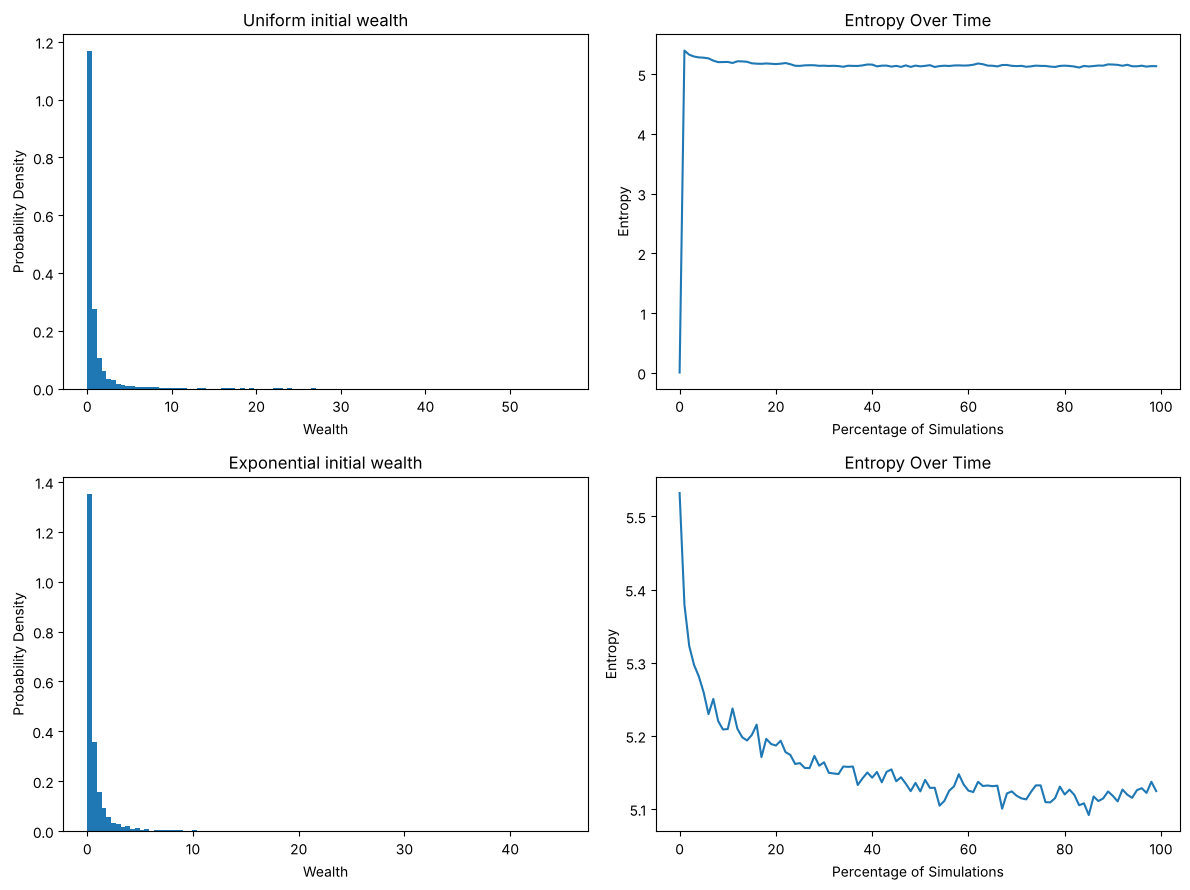

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
plot_simulation_results(uniform_res, bins = 100, title = "Uniform initial wealth", ax = axs[0, :])
plot_simulation_results(exp_res, bins = 100, title = "Exponential initial wealth", ax = axs[1, :])
plt.tight_layout()
plt.show()

### Bulk and tail

The bulk and the tail are shown separately, using the CCDF $P(W > w)$ of every agent (no binning). The cutoffs `bulk_pct` and `tail_pct` at the top of the cell set how much of the population each panel shows.

- **Bulk** (left, bottom `bulk_pct`%): linear axes, with an exponential $e^{-\hat\lambda w}$ fitted to the bulk by least squares. For comparison, the small-wealth theory gives a CCDF rate of $(\beta A - 1)/w_0 = 3$; this only holds for $w \ll w_0$, and the fitted rate is lower because the bulk is already bending towards the tail.
- **Tail** (right, top `tail_pct`%): log-log axes, with a guide of the theoretical slope $-(\beta A - 1) = -1.5$ drawn from the first point of the tail. A Pareto tail is a straight line on these axes.

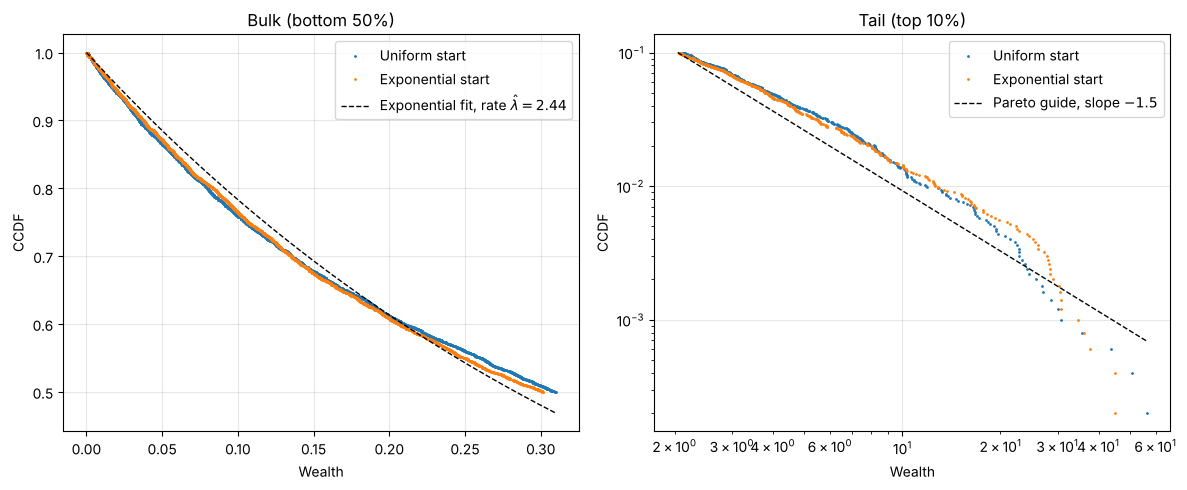

In [4]:
bulk_pct = 50 # bulk panel: bottom bulk_pct% of agents
tail_pct = 10 # tail panel: top tail_pct% of agents

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
runs = [(uniform_res, "Uniform start"), (exp_res, "Exponential start")]
alpha_ccdf = beta * A - 1 # theoretical tail slope of the CCDF
bulk_cut = {label: np.percentile(res[0], bulk_pct) for res, label in runs}
tail_cut = {label: np.percentile(res[0], 100 - tail_pct) for res, label in runs}

### BULK: CCDF of the bottom bulk_pct%, linear axes, with a fitted exponential
xb, yb = [], []
for res, label in runs:
    x, ccdf = prepare_ccdf(res[0])
    mask = x <= bulk_cut[label]
    axs[0].plot(x[mask], ccdf[mask], ".", ms = 2, label = label)
    xb.append(x[mask]); yb.append(ccdf[mask])
xb, yb = np.concatenate(xb), np.concatenate(yb)
lam_fit = -np.sum(xb * np.log(yb)) / np.sum(xb ** 2) # least-squares fit of CCDF = exp(-lam * w)
xs = np.linspace(0, max(bulk_cut.values()), 200)
axs[0].plot(xs, np.exp(-lam_fit * xs), "k--", lw = 1, label = f"Exponential fit, rate $\\hat\\lambda = {lam_fit:.2f}$")
axs[0].set_xlabel("Wealth")
axs[0].set_ylabel("CCDF")
axs[0].set_title(f"Bulk (bottom {bulk_pct}%)")

### TAIL: CCDF of the top tail_pct%, log-log axes, with a slope guide from the first point
for res, label in runs:
    x, ccdf = prepare_ccdf(res[0], pct = 100 - tail_pct)
    axs[1].plot(x, ccdf, ".", ms = 2, label = label)
w_max = max(res[0].max() for res, _ in runs)
xt = np.logspace(np.log10(min(tail_cut.values())), np.log10(w_max), 100)
axs[1].plot(xt, (tail_pct / 100) * (xt / xt[0]) ** (-alpha_ccdf), "k--", lw = 1, label = f"Pareto guide, slope $-{alpha_ccdf:g}$")
axs[1].set_xscale("log")
axs[1].set_yscale("log")
axs[1].set_xlabel("Wealth")
axs[1].set_ylabel("CCDF")
axs[1].set_title(f"Tail (top {tail_pct}%)")

for ax in axs:
    ax.grid(True, alpha = 0.3)
    ax.legend()

plt.tight_layout()
plt.show()

Pareto fits to the upper tail of each run. `alpha` is the maximum-likelihood (Hill) estimate of the CCDF exponent, $P(W > w) \propto w^{-\alpha}$, to compare with the theoretical value $\beta A - 1 = 1.5$.

In [5]:
print("Uniform initial wealth")
uniform_fits = pareto_tail_fits(uniform_res[0])
print("\n\nExponential initial wealth")
exp_fits = pareto_tail_fits(exp_res[0])

Uniform initial wealth

Top 10% tail
xmin = 2.113537888445493
n_tail = 500
alpha = 1.2599833896048616
KS = 0.061561404817608745
p-value = 0.04331488738285305

Top 5% tail
xmin = 3.8921410001847976
n_tail = 250
alpha = 1.4451615410239276
KS = 0.0844542649382582
p-value = 0.05328908498995211

Top 2.5% tail
xmin = 6.940217116630559
n_tail = 125
alpha = 1.8146091558682966
KS = 0.06988556902655108
p-value = 0.5510777599972043

Top 1% tail
xmin = 11.745371354290343
n_tail = 50
alpha = 1.9262411811277174
KS = 0.17382800835842577
p-value = 0.08610247965745232


Exponential initial wealth

Top 10% tail
xmin = 2.0419678318339236
n_tail = 500
alpha = 1.2403124220539885
KS = 0.05649177939973593
p-value = 0.07912151148737301

Top 5% tail
xmin = 3.7865440735564992
n_tail = 250
alpha = 1.3940913317986454
KS = 0.052882512259054215
p-value = 0.4706877020158158

Top 2.5% tail
xmin = 6.5861138972372055
n_tail = 125
alpha = 1.5470801507658314
KS = 0.07517480807013521
p-value = 0.45778458074552064

Top 1% 

### Conclusion

**The starting distribution does not matter.** The two runs begin from opposite ends:

- **Uniform start:** every agent has wealth 1, so there is no inequality at all and the entropy is zero.
- **Exponential start:** the DY equilibrium, already unequal, with a higher entropy than the final state.

The entropy rises from zero in the first run and falls in the second, and both settle at the same value. The final distributions lie on top of each other in both the bulk and the tail, and the fitted tail exponents of the two runs are close at every threshold. The stationary state is set by the exchange rule and the potential, not by where the economy starts. In particular, starting from an exponential distribution, the potential moves the system *away* from the DY equilibrium and into a state with a Pareto tail.

**Bulk and tail.** The bottom half of the population is well described by an exponential. The top 10% is close to a straight line on log-log axes over about a decade of wealth, with a slope near, though somewhat shallower than, the theoretical $-1.5$; the fitted exponents for the top 5–10% are a little below 1.5. At the very top the tail drops off more steeply. This is a finite-size effect: with $N = 5000$ agents, conserved total wealth and exchanges of at most $\bar w$ per step, the extreme tail has not fully filled in.